In [1]:
import numpy as np
from itertools import product
import matplotlib.pyplot as plt

In [2]:
def f(x):
    '''Inputs
            x: 2 by 1 array
        Returns:
            1 if x_0^2 + x_1^2 < 1
            0 otherwise
    '''
    if (x[0]**2 + x[1]**2 < 1):
        return 1
    else:
        return 0
    
        

In [3]:
x = np.array([0.5, 0.5])

x_0_range = np.linspace(-1, 1, 100)
x_1_range = np.linspace(-1, 1, 100)

pairs = np.array(list(product(x_0_range, x_1_range)))

# print(pairs[:,0])
# print(pairs[:,1])
print(len(pairs))

10000


In [4]:
#Draws circle, takes about 30s to run
# for pair in pairs:
#     if f(pair) == 1:
#         plt.scatter(pair[0], pair[1], c='blue')

# plt.show()

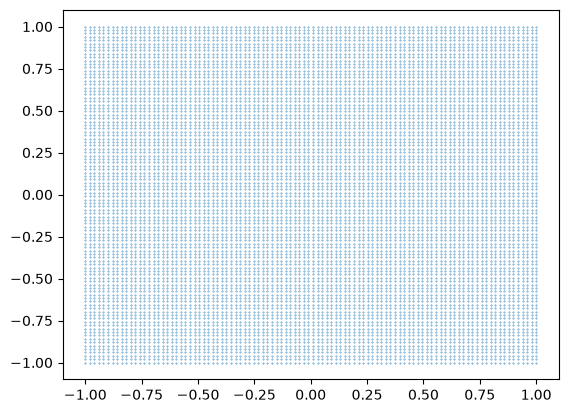

In [5]:
plt.scatter(pairs[:,0], pairs[:,1], s=0.1)

In [6]:
#V = {(x1, x2) : |x1| < 1, |x2| < 1}


def monte_carlo_integration_2d(a1, b1, a2, b2, N, f):
    
    V = np.abs((b1 - a1) * (b2 - a2)) 

    x_0_range = np.random.uniform(-1, 1, N)
    x_1_range = np.random.uniform(-1, 1, N)

    X = list(product(x_0_range, x_1_range))

    fX = []

    for x in X:
        fX.append(f(x))
        
    fX = np.array(fX)

    mean_fX = fX.mean()
    mean_fX_sq = (fX**2).mean()

    sigma = np.sqrt(mean_fX_sq - mean_fX**2)

    integral = V * mean_fX

    error = V*sigma/np.sqrt(N)
    
    return integral, error

a1, a2, b1, b2 = -1, -1, 1, 1

N = 100

integral, error = monte_carlo_integration_2d(a1, b1, a2, b2, N, f)

print(integral)
print(error)

3.2824
0.1534747614430464


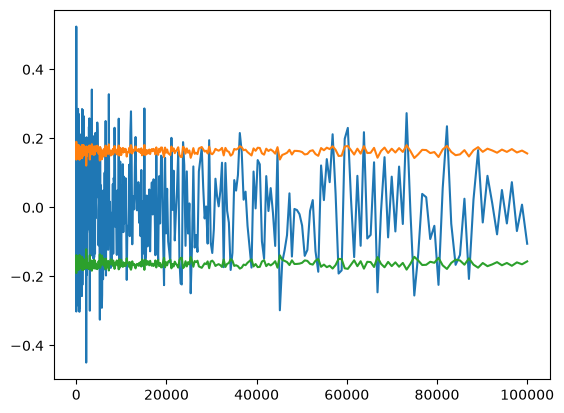

In [17]:
Ns = np.logspace(0, 5, 1000)

integrals, errors = [], []
abs_errors = []


for n in Ns:
    integral, error = monte_carlo_integration_2d(a1, b1, a2, b2, N, f)
    integrals.append(integral)
    abs_errors.append(np.pi - integral)
    errors.append(error)
        
plt.plot(Ns, abs_errors)
plt.plot(Ns, errors)
plt.plot(Ns, [-error for error in errors])